In [1]:
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from researchagent.graph.research import researcher
from researchagent.graph.state import ResearchState
from researchagent.graph.planner import planner
from researchagent.graph.agent import agent, TOOLS
from researchagent.database.checkpointer import get_checkpointer
from researchagent.graph.analyzer import analyzer
from researchagent.graph.verifier import verifier
from researchagent.graph.research_router import research_router
from researchagent.graph.capture_sources import capture_sources
from researchagent.graph.verification_router import verification_router


In [3]:
checkpointer = get_checkpointer()

def should_continue(state: ResearchState): # type: ignore

    last_message = state["messages"][-1]

    if getattr(last_message, "tool_calls", None):
        return "tools"

    return END

In [4]:
builder = StateGraph(ResearchState) # type: ignore

# Nodes
builder.add_node("planner", planner)
builder.add_node("agent", agent)
builder.add_node("researcher", researcher)
builder.add_node("analyzer", analyzer)
builder.add_node("verifier", verifier)
builder.add_node("tools", ToolNode(TOOLS))
builder.add_node(
    "research_tools",
    ToolNode(TOOLS),
)
builder.add_node("capture_sources",capture_sources)

In [5]:
# Start
builder.add_edge(START, "planner")

# Planner → Agent
builder.add_edge("planner", "researcher")
builder.add_conditional_edges(
    "researcher",
    research_router,
    {
        "research_tools": "research_tools",
        "research_done": "capture_sources",
    },
)
builder.add_edge("research_tools", "researcher")

builder.add_edge("capture_sources", "analyzer")
builder.add_edge("analyzer", "verifier")
builder.add_conditional_edges(
    "verifier",
    verification_router,
    {
        "pass": "agent",
        "needs_more_research": "researcher",
    },
)


# Agent → Tools OR End
builder.add_conditional_edges(
    "agent",
    should_continue,
    {
        "tools": "tools",
        END: END,
    },
)

# Tools → Agent
builder.add_edge("tools", "agent")



graph = builder.compile(
    checkpointer=checkpointer
)

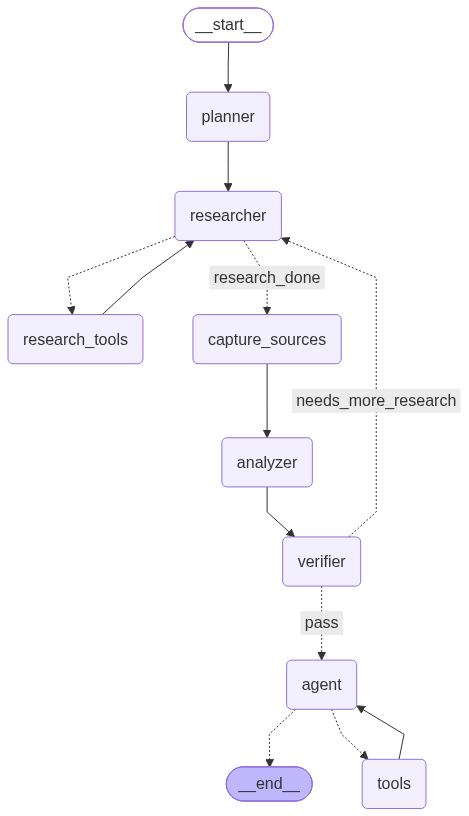

In [6]:
graph